In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

print("Libraries imported successfully")


Libraries imported successfully


In [2]:

df = pd.read_csv("Mall_Customers.csv")

print(df.head())
print("\nDataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())


   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Dataset Shape: (200, 5)

Column Names: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


In [3]:

print("Dataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB
None

Statistical Summary:
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.5

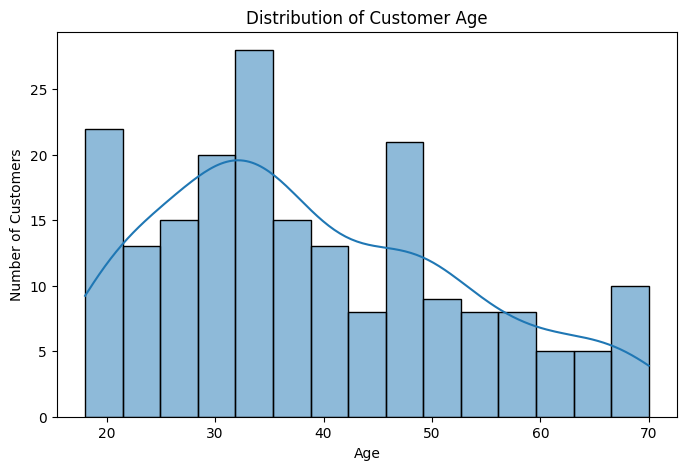

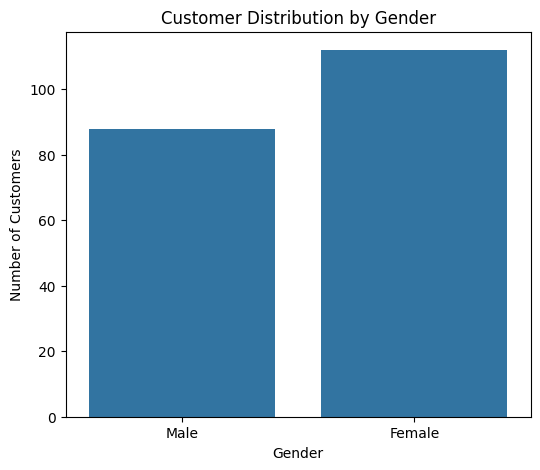

In [4]:

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Age", bins=15, kde=True)
plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

plt.figure(figsize=(6, 5))
sns.countplot(data=df, x="Gender")
plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.show()


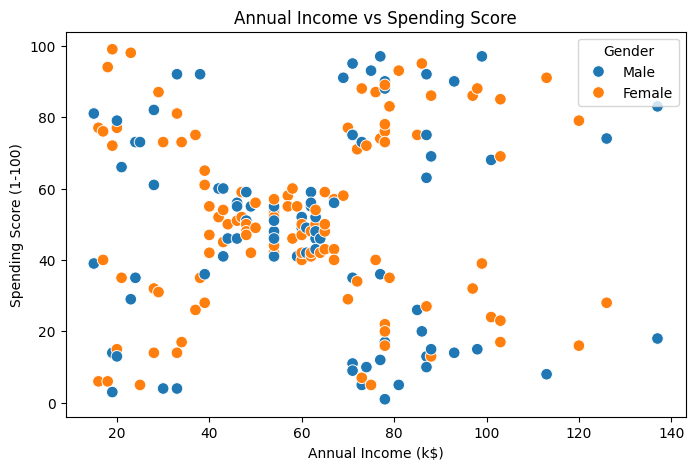

In [5]:

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Gender",
    s=70
)
plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()


In [6]:

X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

print(X.head())
print("\nFeatures Shape:", X.shape)


   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40

Features Shape: (200, 2)


In [7]:

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardization completed")
print("Scaled data shape:", X_scaled.shape)


Standardization completed
Scaled data shape: (200, 2)


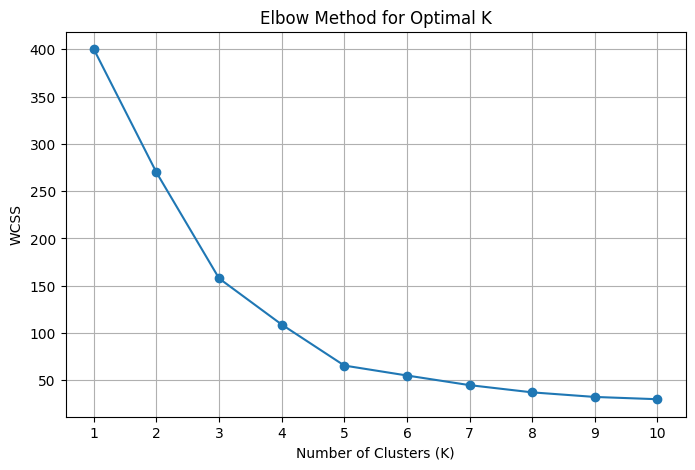

In [8]:

wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


In [9]:

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print(df[["Annual Income (k$)", "Spending Score (1-100)", "Cluster"]].head(10))
print("\nCustomers in Each Cluster:")
print(df["Cluster"].value_counts().sort_index())


   Annual Income (k$)  Spending Score (1-100)  Cluster
0                  15                      39        4
1                  15                      81        2
2                  16                       6        4
3                  16                      77        2
4                  17                      40        4
5                  17                      76        2
6                  18                       6        4
7                  18                      94        2
8                  19                       3        4
9                  19                      72        2

Customers in Each Cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


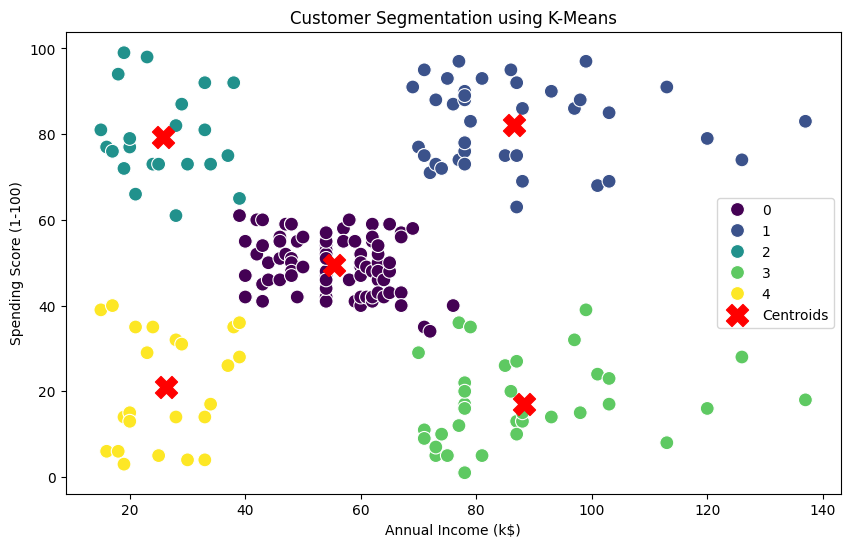

In [11]:

centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="viridis",
    s=100
)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    s=250,
    marker="X",
    color="red",
    label="Centroids"
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.show()


In [12]:

score = silhouette_score(X_scaled, df["Cluster"])

print("Silhouette Score:", round(score, 3))


Silhouette Score: 0.555


In [13]:

cluster_summary = df.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

print(cluster_summary)


         Customer_Count  Average_Age  Average_Income  Average_Spending_Score
Cluster                                                                     
0                    81        42.72           55.30                   49.52
1                    39        32.69           86.54                   82.13
2                    22        25.27           25.73                   79.36
3                    35        41.11           88.20                   17.11
4                    23        45.22           26.30                   20.91


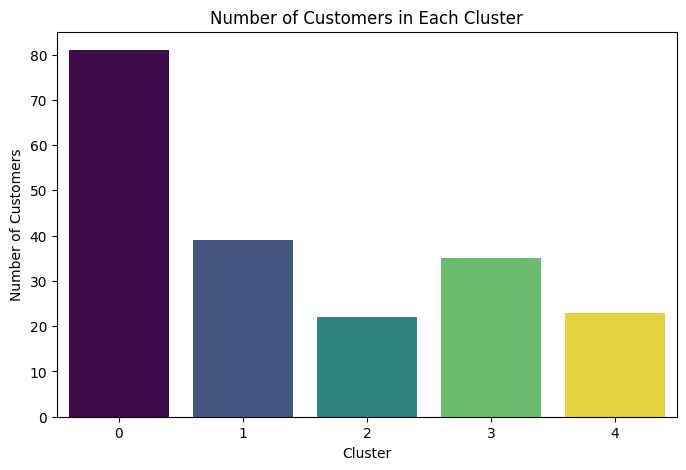

In [14]:

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Cluster", hue="Cluster", palette="viridis", legend=False)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.show()


In [15]:

score = silhouette_score(X_scaled, df["Cluster"])

print("Silhouette Score:", round(score, 3))


Silhouette Score: 0.555


In [16]:

df.to_csv("Customer_Segmentation_Results.csv", index=False)
cluster_summary.to_csv("Cluster_Summary.csv")

print("Customer segmentation results saved successfully")


Customer segmentation results saved successfully


In [17]:

silhouette_scores = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

results = pd.DataFrame({
    "Number of Clusters": range(2, 11),
    "Silhouette Score": silhouette_scores
})

print(results.round(3))


   Number of Clusters  Silhouette Score
0                   2             0.321
1                   3             0.467
2                   4             0.494
3                   5             0.555
4                   6             0.540
5                   7             0.528
6                   8             0.455
7                   9             0.457
8                  10             0.443


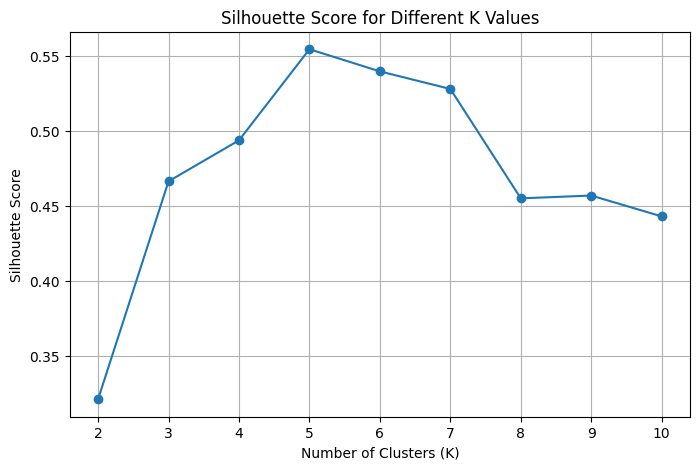

In [18]:

plt.figure(figsize=(8, 5))

plt.plot(
    results["Number of Clusters"],
    results["Silhouette Score"],
    marker="o"
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()


In [19]:

best_row = results.loc[results["Silhouette Score"].idxmax()]

print("Best K based on Silhouette Score:", int(best_row["Number of Clusters"]))
print("Best Silhouette Score:", round(best_row["Silhouette Score"], 3))


Best K based on Silhouette Score: 5
Best Silhouette Score: 0.555


In [20]:

results.to_csv("K_Comparison_Results.csv", index=False)

print("Evaluation results saved successfully")


Evaluation results saved successfully
